In [1]:
# Datheon Internship - Task 1
# Multi-Class Classification using Iris Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:

# Step 2: Load Dataset

df = pd.read_csv("iris.txt")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:

# Step 3: Exploratory Data Analysis (EDA)

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Count:")
print(df["species"].value_counts())

print("\nStatistical Summary:")
df.describe()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species Count:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


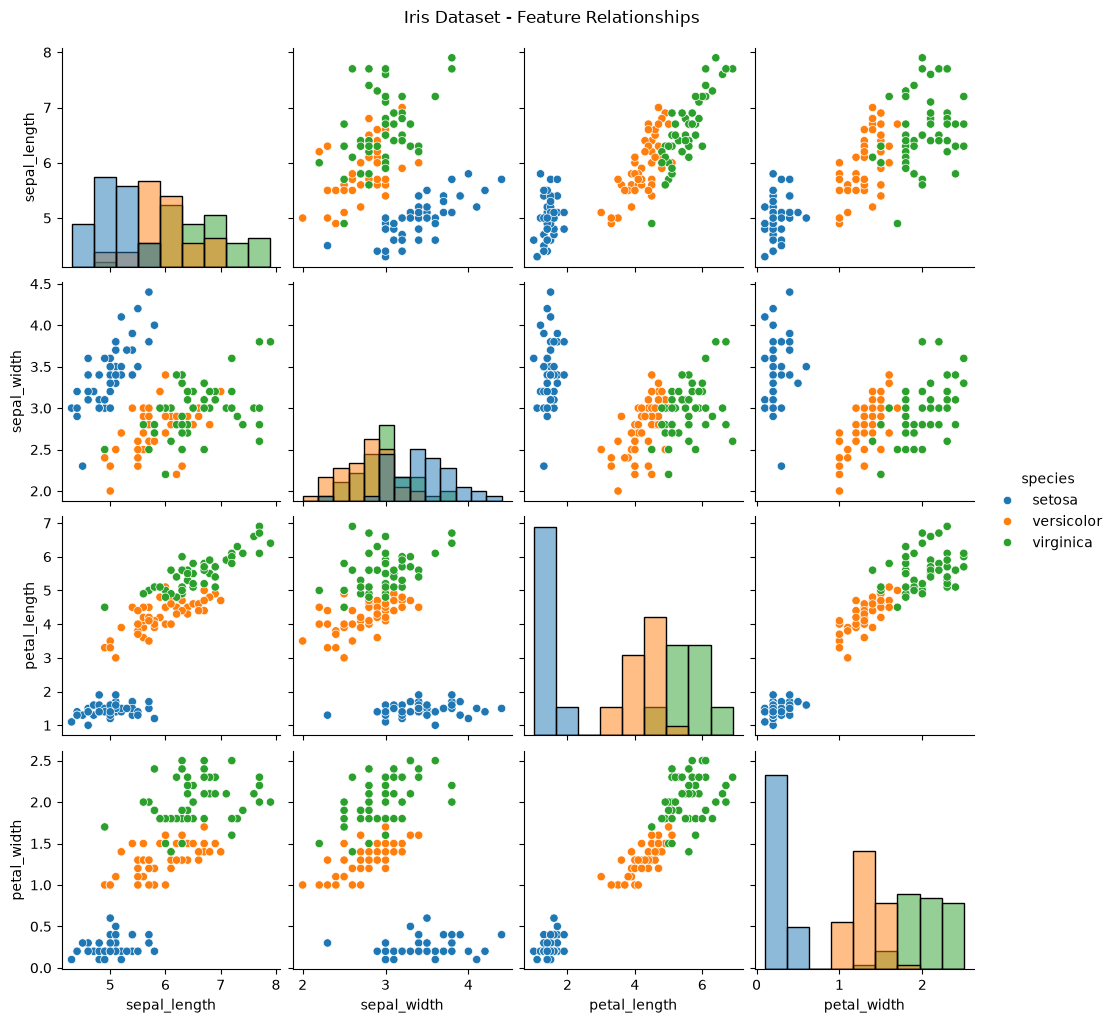

In [6]:

# Step 4: Pairplot Visualization

sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Iris Dataset - Feature Relationships", y=1.02)
plt.show()


In [7]:

# Step 5: Separate Features and Target

X = df.drop("species", axis=1)
y = df["species"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)



Training data shape: (120, 4)
Testing data shape: (30, 4)


In [8]:

# Step 6: Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)


Feature scaling completed!
Scaled training data shape: (120, 4)
Scaled testing data shape: (30, 4)


In [9]:

# Step 7: Train Machine Learning Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name} training completed!")

print("\nAll models trained successfully!")



Logistic Regression training completed!
Decision Tree training completed!

All models trained successfully!


In [10]:

# Step 8: Model Evaluation

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(3))


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933


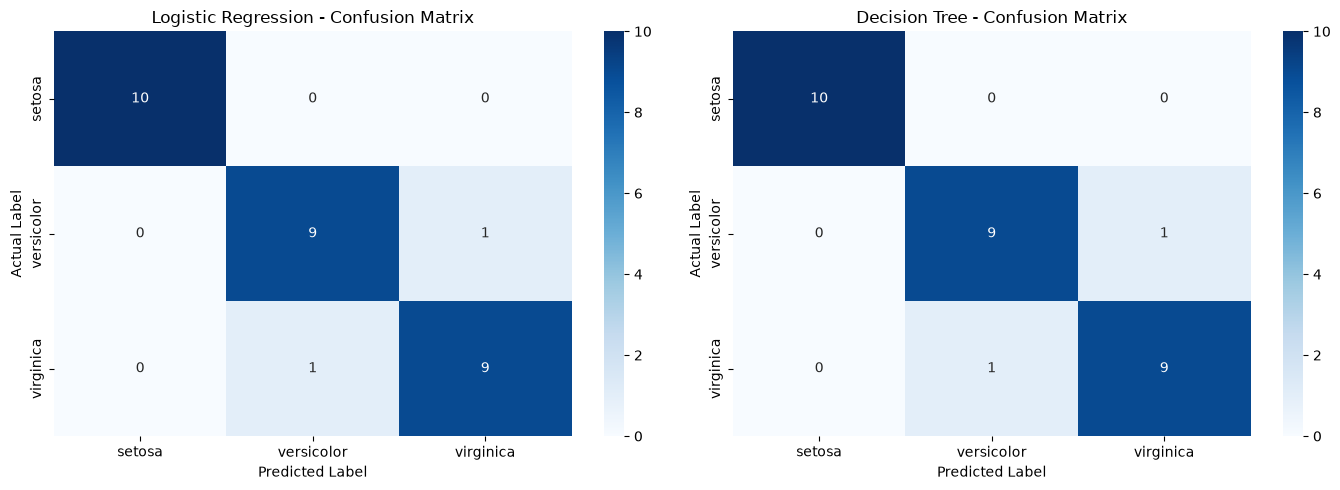

In [11]:

# Step 9: Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()



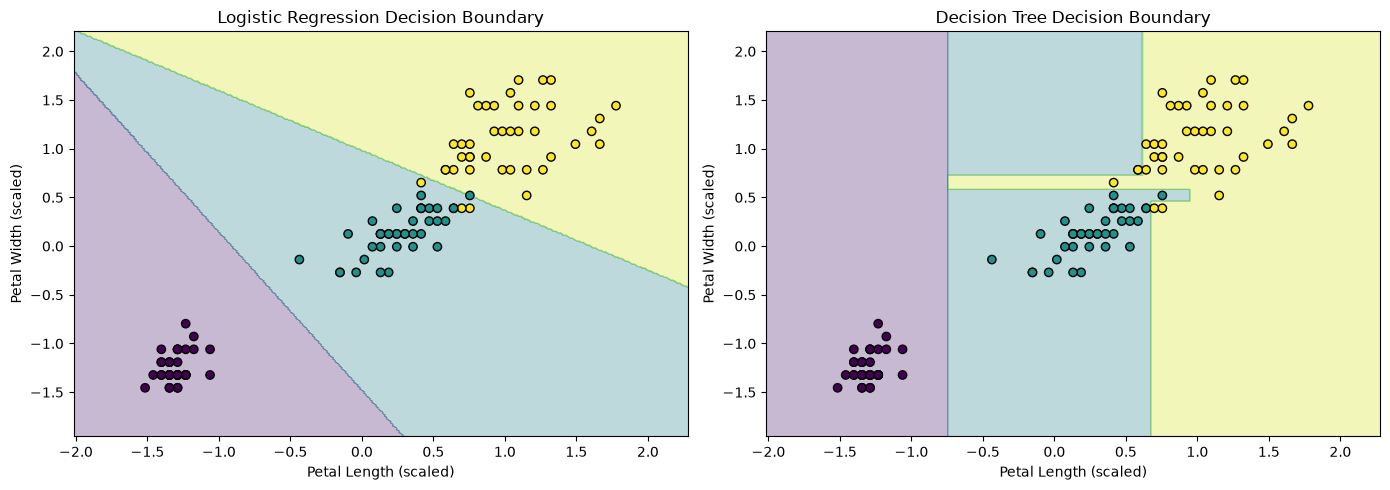

In [12]:

# Step 10: Decision Boundary Visualization

from matplotlib.colors import ListedColormap
from sklearn.preprocessing import LabelEncoder

# Use petal length and petal width for 2D visualization
X_2d = df[["petal_length", "petal_width"]].values
y_2d = LabelEncoder().fit_transform(df["species"])

# Split the 2D data
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# Scale the 2D data
scaler_2d = StandardScaler()
X2_train_scaled = scaler_2d.fit_transform(X2_train)
X2_test_scaled = scaler_2d.transform(X2_test)

# Train models using the two selected features
models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models_2d.items()):
    model.fit(X2_train_scaled, y2_train)

    x_min = X2_train_scaled[:, 0].min() - 0.5
    x_max = X2_train_scaled[:, 0].max() + 0.5
    y_min = X2_train_scaled[:, 1].min() - 0.5
    y_max = X2_train_scaled[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(
        X2_train_scaled[:, 0],
        X2_train_scaled[:, 1],
        c=y2_train,
        cmap="viridis",
        edgecolors="black"
    )

    ax.set_title(f"{name} Decision Boundary")
    ax.set_xlabel("Petal Length (scaled)")
    ax.set_ylabel("Petal Width (scaled)")

plt.tight_layout()
plt.show()



## Conclusion

The Iris dataset was used to perform multi-class classification using Logistic Regression and Decision Tree algorithms. Exploratory Data Analysis (EDA) was performed using Pandas, and feature relationships were visualized using Seaborn pairplots.

The dataset was divided into 80% training data and 20% testing data. StandardScaler was applied for feature scaling. Both classification models were evaluated using Accuracy, Precision, Recall, and F1 Score. Confusion matrices and decision boundary plots were used to visualize model performance.

Finally, the performance metrics were compared to understand the effectiveness of both classification algorithms in predicting Iris flower species.
